Display a stacked bar chart comparing sex vs target using only raw Matplotlib patches, ensuring proper alignment, color coding, and proportion calculations without using high-level bar chart functions. give ans in ipynb

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Dataset is in the same folder as the notebook
df = pd.read_csv("heart_disease_with_risk_factor.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   patient_id  age     sex                cp  trestbps  chol    fbs restecg  \
0           1   69    Male    Typical Angina       188   266  False  Normal   
1           2   56    Male    Typical Angina       105   237  False     LVH   
2           3   57  Female    Typical Angina       191   538  False     LVH   
3           4   34  Female    Typical Angina       139   559   True     LVH   
4           5   34  Female  Non-anginal Pain       167   224  False  Normal   

   thalach exang  oldpeak        slope     ca               thal  target  \
0      106    No      4.2  Downsloping   Zero  Reversible Defect       1   
1       77    No      4.4  Downsloping  Three             Normal       0   
2      179   Yes      1.7    Upsloping    Two             Normal       1   
3      138    No      4.5  Downsloping   Zero       Fixed Defect       0   
4      129   Yes      6.1    Upsloping   Zero       Fixed Defect       1   

   chol_percentile  thalach_percentile 

Dataset loaded successfully!
   patient_id  age     sex                cp  trestbps  chol    fbs restecg  \
0           1   69    Male    Typical Angina       188   266  False  Normal   
1           2   56    Male    Typical Angina       105   237  False     LVH   
2           3   57  Female    Typical Angina       191   538  False     LVH   
3           4   34  Female    Typical Angina       139   559   True     LVH   
4           5   34  Female  Non-anginal Pain       167   224  False  Normal   

   thalach exang  oldpeak        slope     ca               thal  target  \
0      106    No      4.2  Downsloping   Zero  Reversible Defect       1   
1       77    No      4.4  Downsloping  Three             Normal       0   
2      179   Yes      1.7    Upsloping    Two             Normal       1   
3      138    No      4.5  Downsloping   Zero       Fixed Defect       0   
4      129   Yes      6.1    Upsloping   Zero       Fixed Defect       1   

   chol_percentile  thalach_percentile 

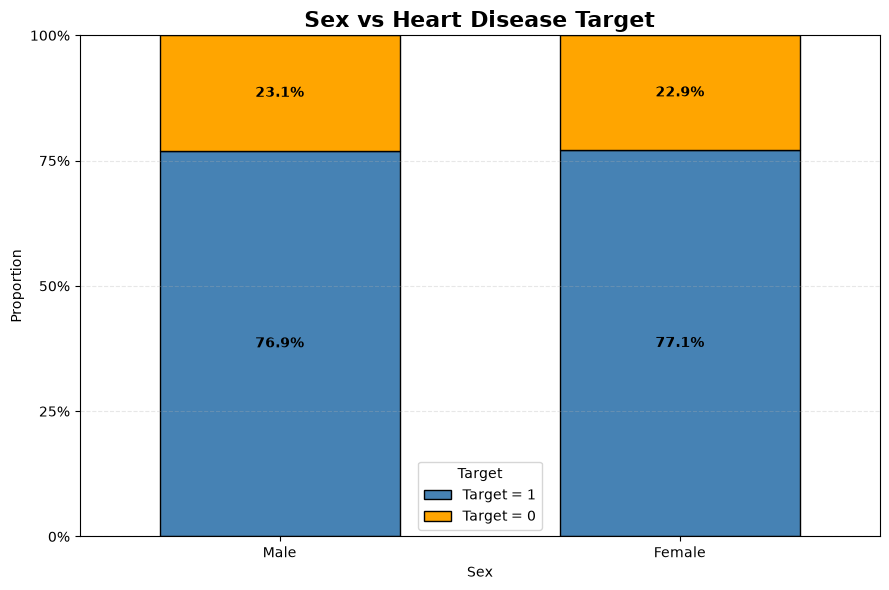

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Load dataset
df = pd.read_csv("heart_disease_with_risk_factor.csv")

print("Dataset loaded successfully!")
print(df.head())

# Find unique categories
sex_categories = []
target_categories = []

for value in df["sex"]:
    if pd.isna(value):
        value = "Unknown"

    if value not in sex_categories:
        sex_categories.append(value)

for value in df["target"]:
    if pd.isna(value):
        value = "Unknown"

    if value not in target_categories:
        target_categories.append(value)

print("Sex categories:", sex_categories)
print("Target categories:", target_categories)

# Calculate frequencies
frequency_table = {}

for sex in sex_categories:

    frequency_table[sex] = {}

    for target in target_categories:

        count = 0

        for i in range(len(df)):

            current_sex = df["sex"].iloc[i]
            current_target = df["target"].iloc[i]

            if pd.isna(current_sex):
                current_sex = "Unknown"

            if pd.isna(current_target):
                current_target = "Unknown"

            if (
                current_sex == sex
                and current_target == target
            ):
                count += 1

        frequency_table[sex][target] = count

print("\nFrequency Table:")

for sex in sex_categories:
    print(sex, frequency_table[sex])

# Create chart
fig, ax = plt.subplots(figsize=(9, 6))

bar_width = 0.6

positions = []

for i in range(len(sex_categories)):
    positions.append(i)

# Set colors
colors = []

for i in range(len(target_categories)):

    if i == 0:
        colors.append("steelblue")

    elif i == 1:
        colors.append("orange")

    else:
        colors.append("seagreen")

# Draw stacked bars
for i in range(len(sex_categories)):

    sex = sex_categories[i]

    total = 0

    for target in target_categories:
        total += frequency_table[sex][target]

    bottom = 0

    for j in range(len(target_categories)):

        target = target_categories[j]

        frequency = frequency_table[sex][target]

        if total > 0:
            proportion = frequency / total
        else:
            proportion = 0

        rectangle = Rectangle(
            (
                positions[i] - bar_width / 2,
                bottom
            ),
            bar_width,
            proportion,
            facecolor=colors[j],
            edgecolor="black",
            linewidth=1
        )

        ax.add_patch(rectangle)

        # Add percentage
        if proportion > 0:

            ax.text(
                positions[i],
                bottom + proportion / 2,
                f"{proportion * 100:.1f}%",
                ha="center",
                va="center",
                fontweight="bold"
            )

        bottom += proportion

# Configure axes
ax.set_xlim(
    -0.5,
    len(sex_categories) - 0.5
)

ax.set_ylim(0, 1)

ax.set_xticks(positions)

ax.set_xticklabels(sex_categories)

ax.set_yticks(
    [0, 0.25, 0.50, 0.75, 1.00]
)

ax.set_yticklabels(
    ["0%", "25%", "50%", "75%", "100%"]
)

# Add labels
ax.set_title(
    "Sex vs Heart Disease Target",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Sex")
ax.set_ylabel("Proportion")

# Create legend
legend_patches = []

for i in range(len(target_categories)):

    patch = Rectangle(
        (0, 0),
        1,
        1,
        facecolor=colors[i],
        edgecolor="black"
    )

    legend_patches.append(patch)

ax.legend(
    legend_patches,
    [
        f"Target = {target}"
        for target in target_categories
    ],
    title="Target"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()